In [3]:
from pathlib import Path
import pydicom

raw = Path(r"C:\Users\micha\PycharmProjects\lung-ct-classification\data\raw\lung_pet_ct_dx\Lung_Dx-A0001")
print(raw.exists())

ct_files = sorted(raw.rglob("*.dcm"))
print(len(ct_files))

ds = pydicom.dcmread(ct_files[0])
print(ds.SOPInstanceUID)
print(ds.Rows, ds.Columns, ds.RescaleSlope, ds.RescaleIntercept)

True
130
1.3.6.1.4.1.14519.5.2.1.6655.2359.226668662204904352011722629799
512 512 1 -1024


In [2]:
import os
print(os.getcwd())
print(raw.exists())
print([p.name for p in raw.rglob("*")][:10])

C:\Users\micha\PycharmProjects\lung-ct-classification\notebooks\notebooks
False
[]


In [2]:
from pathlib import Path
import pydicom

base = Path(r"C:\Users\micha\PycharmProjects\lung-ct-classification\data")
raw = base / "raw" / "lung_pet_ct_dx" / "Lung_Dx-A0001"
ann_dir = base / "annotations"

ann_ids = {p.stem for p in ann_dir.rglob("*.xml")}
print(len(ann_ids))

ct_files = [p for p in raw.rglob("*.dcm") if p.parent.name.startswith("CT_")]
print(len(ct_files))

matched = []
for p in ct_files:
    uid = pydicom.dcmread(p, stop_before_pixels=True).SOPInstanceUID
    if uid in ann_ids:
        matched.append((uid, p))
print(len(matched))

31400
128
20


In [5]:
print(ann_dir.exists())
files = list(ann_dir.rglob("*.xml"))
print(len(files))
print([str(p.relative_to(ann_dir)) for p in files[:3]])

False
0
[]


In [6]:
data_dir = Path(r"C:\Users\micha\PycharmProjects\lung-ct-classification\data")
for p in data_dir.iterdir():
    print(p.name, p.is_dir())

raw True


-1024.0 2289.0


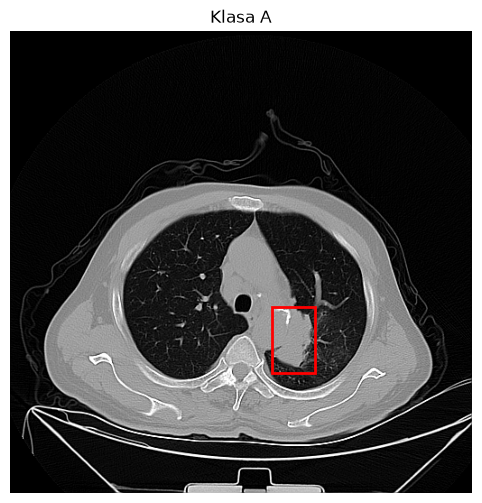

In [3]:
import numpy as np
import matplotlib.pyplot as plt
import xml.etree.ElementTree as ET
from matplotlib.patches import Rectangle

uid, path = matched[10]
xml_path = next(ann_dir.rglob(f"{uid}.xml"))
obj = ET.parse(xml_path).getroot().find("object")
label = obj.find("name").text
bb = obj.find("bndbox")
xmin, ymin, xmax, ymax = [int(bb.find(t).text) for t in ("xmin", "ymin", "xmax", "ymax")]

ds = pydicom.dcmread(path)
hu = ds.pixel_array * float(ds.RescaleSlope) + float(ds.RescaleIntercept)
print(hu.min(), hu.max())

lo, hi = -1400, 700   # okno płucne: poziom -700, szerokość 1400
img = (np.clip(hu, lo, hi) - lo) / (hi - lo)

fig, ax = plt.subplots(figsize=(6, 6))
ax.imshow(img, cmap="gray")
ax.add_patch(Rectangle((xmin, ymin), xmax - xmin, ymax - ymin, fill=False, edgecolor="red", linewidth=2))
ax.set_title(f"Klasa {label}")
ax.axis("off")
plt.show()

In [5]:
from collections import Counter

counts = Counter()
mismatch = 0
for p in ann_dir.rglob("*.xml"):
    letter = ET.parse(p).getroot().find("object/name").text
    counts[letter] += 1
    if letter != p.parent.name[0]:
        mismatch += 1

print(counts)
print("niezgodne:", mismatch)

ParseError: not well-formed (invalid token): line 1, column 0 (<string>)

In [6]:
counts = Counter()
mismatch = 0
bad = []
for p in ann_dir.rglob("*.xml"):
    try:
        letter = ET.parse(p).getroot().find("object/name").text
    except Exception as e:
        bad.append((p, type(e).__name__))
        continue
    counts[letter] += 1
    if letter != p.parent.name[0]:
        mismatch += 1

print(counts)
print("niezgodne:", mismatch)
print("uszkodzone:", len(bad))
for p, e in bad[:5]:
    print(p.relative_to(ann_dir), e, p.stat().st_size, p.read_bytes()[:40])

Counter({'A': 12981, 'a': 7901, 'G': 5266, 'B': 2244, 'g': 2089, 'b': 860, 'E': 201, 'Q': 10, 'A0192': 9})
niezgodne: 10890
uszkodzone: 1
A0024\1.3.6.1.4.1.14519.5.2.1.6655.2359.148117780944430339778694852523.xml ParseError 4096 b'\x00\x05\x16\x07\x00\x02\x00\x00Mac OS X        \x00\x02\x00\x00\x00\t\x00\x00\x002\x00\x00\x0e\xb0\x00\x00'


In [7]:
pairs = Counter()
odd = Counter()
for p in ann_dir.rglob("*.xml"):
    try:
        letter = ET.parse(p).getroot().find("object/name").text
    except Exception:
        continue
    folder = p.parent.name[0]
    if letter.upper() != folder:
        pairs[(folder, letter)] += 1
        odd[p.parent.name] += 1

print(pairs)
print(odd)

Counter({('B', 'a'): 33, ('A', 'B'): 21, ('A', 'Q'): 10, ('A', 'A0192'): 9, ('A', 'g'): 4})
Counter({'B0033': 33, 'A0264': 21, 'A0118': 10, 'A0192': 9, 'A0212': 4})
